<a href="https://colab.research.google.com/github/Nyangweso1/my-portfolio/blob/main/prudence__afya_bora_hospital_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Afya Bora Hospital: Patient Admissions Diagnostic


**Goal:** clean the raw admissions data, explore it, find the drivers of `Treatment_cost`, and give management actionable insights on pricing, staffing and insurance.



**Import libraries**

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

---
# PART 1: Data Parsing

A legacy system exports admissions as **one long string**. Approach:
1. Split the string into records on the `;` delimiter.
2. For each record, use a regular expression to pull out every `key: value` pair (a key is a word, a value runs up to the next comma or semicolon).
3. Build a DataFrame, then enforce data types.

In [ ]:
raw_string = """patient: John Kamau, age: 45, gender: M, department: Cardiology,
 diagnosis: Hypertension, treatment_cost: 1250.50,
 payment_method: Insurance, admission_date: 2025-06-15;
 patient: Mary Wanjiku, age: 32, gender: F, department: Pediatrics,
 diagnosis: Malaria, treatment_cost: 480.00,
 payment_method: Cash, admission_date: 2025-06-16;
 patient: Peter Otieno, age: 67, gender: M, department: Orthopedics,
 diagnosis: Fracture, treatment_cost: 3200.75,
 payment_method: Mobile Money, admission_date: 2025-06-17"""

rows = []

# each patient record ends with ";"
for record in raw_string.split(";"):
    row = {}
    # each field inside a record is separated by ","
    for field in record.split(","):
        key, value = field.split(":", 1)      # split at the first ":" only
        row[key.strip()] = value.strip()
    rows.append(row)

print(len(rows), "records found")
print(rows[0])

3 records found
{'patient': 'John Kamau', 'age': '45', 'gender': 'M', 'department': 'Cardiology', 'diagnosis': 'Hypertension', 'treatment_cost': '1250.50', 'payment_method': 'Insurance', 'admission_date': '2025-06-15'}


In [ ]:
# loading into a DataFrame
df_parsed = pd.DataFrame(rows)
df_parsed.columns = [name.capitalize() for name in df_parsed.columns]

# fixing data types
df_parsed["Age"] = df_parsed["Age"].astype(int)
df_parsed["Treatment_cost"] = df_parsed["Treatment_cost"].astype(float)
df_parsed["Admission_date"] = pd.to_datetime(df_parsed["Admission_date"])

print(df_parsed.dtypes)
df_parsed.head()

Patient                   object
Age                        int64
Gender                    object
Department                object
Diagnosis                 object
Treatment_cost           float64
Payment_method            object
Admission_date    datetime64[ns]
dtype: object


,Patient,Age,Gender,Department,Diagnosis,Treatment_cost,Payment_method,Admission_date
0,John Kamau,45,M,Cardiology,Hypertension,1250.50,Insurance,2025-06-15
1,Mary Wanjiku,32,F,Pediatrics,Malaria,480.00,Cash,2025-06-16
2,Peter Otieno,67,M,Orthopedics,Fracture,3200.75,Mobile Money,2025-06-17


---
# PART 2: Data Wrangling and Preparation
## Step 1: Load and inspect

In [ ]:
from google.colab import files
import os
import pandas as pd


print("Please select and upload your CSV file:")
uploaded = files.upload()
FILE = list(uploaded.keys())[0]

df_raw = pd.read_csv(FILE)
df_raw.columns = df_raw.columns.str.lower()      # lowercase column names
print("Loaded shape:", df_raw.shape)


Please select and upload your CSV file:


Saving afya_bora_hospital.csv to afya_bora_hospital (1).csv
Loaded shape: (250, 13)


In [ ]:
df_raw.head(10)

,patient_id,age,gender,department,diagnosis,treatment_cost,admission_date,discharge_date,admission_time,discharge_time,payment_method,insurance_status,satisfaction_score
0,P0001,12,male,General,Malaria,ERROR,2025-11-24,NaN,08:15,13:15,Card,Insured,2.0
1,P0002,UNKNOWN,F,General,Pneumonia,492.36,2025-09-16,NaN,06:45,11:45,Mobile Money,Insured,3.0
2,P0003,49,M,Emergency,Diabetes,459.99,2025-02-22,2025-02-23,11:30,21:30,Cash,UNKNOWN,3.0
3,P0004,59,UNKNOWN,Orthopedics,Fracture,459.99,2025-10-23,2025-10-26,01:15,15:15,Cash,Insured,NaN
4,P0005,82,UNKNOWN,Emergency,Hypertension,1355.4,2025-05-17,2025-05-28,20:00,18:00,UNKNOWN,Insured,2.0
5,P0006,51,UNKNOWN,General,Fracture,876,2025-01-17,2025-01-29,08:00,12:00,UNKNOWN,Insured,NaN
6,P0007,12,M,Cardiology,Fracture,386.62,2025-10-15,2025-10-23,18:45,22:45,Insurance,UNKNOWN,4.0
7,P0008,UNKNOWN,UNKNOWN,Cardiology,ERROR,766.86,2025-11-02,2025-11-03,19:45,15:45,Insurance,UNKNOWN,3.0
8,P0009,81,Male,Emergency,Hypertension,635.67,2025-02-27,2025-03-03,14:00,00:00,UNKNOWN,Insured,5.0
9,P0010,40,F,Cardiology,Hypertension,98.59,2025-09-29,NaN,10:45,13:45,Cash,Insured,1.0


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   patient_id          250 non-null    object 
 1   age                 250 non-null    object 
 2   gender              250 non-null    object 
 3   department          250 non-null    object 
 4   diagnosis           250 non-null    object 
 5   treatment_cost      245 non-null    object 
 6   admission_date      250 non-null    object 
 7   discharge_date      238 non-null    object 
 8   admission_time      250 non-null    object 
 9   discharge_time      250 non-null    object 
 10  payment_method      250 non-null    object 
 11  insurance_status    250 non-null    object 
 12  satisfaction_score  204 non-null    float64
dtypes: float64(1), object(12)
memory usage: 25.5+ KB


In [ ]:
print(df_raw.isnull().sum())

patient_id             0
age                    0
gender                 0
department             0
diagnosis              0
treatment_cost         5
admission_date         0
discharge_date        12
admission_time         0
discharge_time         0
payment_method         0
insurance_status       0
satisfaction_score    46
dtype: int64


In [ ]:
# count "ERROR" in every column
print((df_raw == "ERROR").sum())

# rows that contain at least one ERROR
has_error = (df_raw == "ERROR").any(axis=1)
print("\nRows with an ERROR:", has_error.sum())

# "UNKNOWN" is another hidden missing value
print("\nUNKNOWN counts:")
print((df_raw == "UNKNOWN").sum())

df_raw[has_error].head()

patient_id             0
age                    0
gender                 0
department             0
diagnosis             28
treatment_cost        22
admission_date         0
discharge_date         0
admission_time         0
discharge_time         0
payment_method         0
insurance_status       0
satisfaction_score     0
dtype: int64

Rows with an ERROR: 46

UNKNOWN counts:
patient_id             0
age                    9
gender                51
department             0
diagnosis              0
treatment_cost         0
admission_date         0
discharge_date         0
admission_time         0
discharge_time         0
payment_method        50
insurance_status      88
satisfaction_score     0
dtype: int64


,patient_id,age,gender,department,diagnosis,treatment_cost,admission_date,discharge_date,admission_time,discharge_time,payment_method,insurance_status,satisfaction_score
0,P0001,12,male,General,Malaria,ERROR,2025-11-24,NaN,08:15,13:15,Card,Insured,2.0
7,P0008,UNKNOWN,UNKNOWN,Cardiology,ERROR,766.86,2025-11-02,2025-11-03,19:45,15:45,Insurance,UNKNOWN,3.0
10,P0011,78,Female,Pediatrics,ERROR,247.9,2025-09-06,2025-09-19,17:15,10:15,Mobile Money,UNKNOWN,2.0
14,P0015,71,M,Cardiology,ERROR,365.02,2025-04-09,2025-04-12,04:45,04:45,Insurance,Insured,2.0
15,P0016,59,Male,General,ERROR,583.52,2025-03-27,2025-04-02,06:45,14:45,Card,Uninsured,2.0


**Observations**
- Missing values: `Treatment_cost` has blanks, `Discharge_date` has blanks, and `Satisfaction_score` is the most incomplete column.
- `"ERROR"` appears in only two columns, `Treatment_cost` and `Diagnosis`.
- Missing data is also hidden behind the text `"UNKNOWN"` (Age, Gender, Payment_method, Insurance_status), so `isnull()` alone under-counts the problem.
- `Treatment_cost` and `Age` are stored as text (`object`/`str`) because of `$`, `,`, `ERROR` and `UNKNOWN`, so they cannot be used in calculations until cleaned.

## Step 2: Clean numeric columns

In [ ]:
df = df_raw.copy()

# treatment_cost: remove $ and commas, ERROR -> NaN, then convert to float
df["treatment_cost"] = df["treatment_cost"].str.replace("$", "", regex=False)
df["treatment_cost"] = df["treatment_cost"].str.replace(",", "", regex=False)
df["treatment_cost"] = df["treatment_cost"].replace("ERROR", np.nan)
df["treatment_cost"] = df["treatment_cost"].astype(float)

# age: UNKNOWN -> NaN, then Int64 (an integer type that allows missing values)
df["age"] = df["age"].replace("UNKNOWN", np.nan)
df["age"] = df["age"].astype(float).astype("Int64")

# satisfaction score: whole numbers with blanks
df["satisfaction_score"] = df["satisfaction_score"].astype("Int64")

In [ ]:
print(df[["treatment_cost", "age", "satisfaction_score"]].dtypes)

# any text (object/str) columns left among the numeric ones?
print("\nObject columns left:", list(df[["treatment_cost", "age"]].select_dtypes(include=["object", "string"]).columns))

print("\nMissing values now:")
print(df[["treatment_cost", "age", "satisfaction_score"]].isnull().sum())

treatment_cost        float64
age                     Int64
satisfaction_score      Int64
dtype: object

Object columns left: []

Missing values now:
treatment_cost        27
age                    9
satisfaction_score    46
dtype: int64


In [ ]:
# how many rows did the cleaning change? (counted from the raw data)
n_symbol = df_raw["treatment_cost"].str.contains("[$,]", na=False).sum()
n_error = (df_raw["treatment_cost"] == "ERROR").sum()
n_blank = df_raw["treatment_cost"].isnull().sum()
n_age = (df_raw["age"] == "UNKNOWN").sum()

print("treatment_cost had $ or , (value kept):", n_symbol)
print("treatment_cost was ERROR (-> NaN):     ", n_error)
print("treatment_cost was already blank:      ", n_blank)
print("age was UNKNOWN (-> NaN):              ", n_age)

no_cost = df["treatment_cost"].isnull().sum()
print("\nRows with no usable cost:", no_cost, "of", len(df), "=", round(no_cost / len(df) * 100, 1), "%")

treatment_cost had $ or , (value kept): 11
treatment_cost was ERROR (-> NaN):      22
treatment_cost was already blank:       5
age was UNKNOWN (-> NaN):               9

Rows with no usable cost: 27 of 250 = 10.8 %


**Approach and justification**
- `$` and `,` are formatting only, so removing them **recovers the real value** (no information lost).
- `"ERROR"` is a system failure with no recoverable value, so it becomes `NaN`.
- I did **not** impute `Treatment_cost`: it is the target variable, and filling it with a mean or median would invent costs and shrink the real variation. Rows with a missing cost are simply left out of cost-based charts and statistics (pandas/seaborn skip `NaN` automatically), but kept for all other counts.
- `Age` has only a few `UNKNOWN` values, so I also left them as `NaN` rather than guessing. `Int64` (capital I) is used because a normal integer column cannot hold missing values.

## Step 3: Clean categorical data (`payment_method`)

In [ ]:
print(df["payment_method"].value_counts())

payment_method
UNKNOWN         50
Insurance       45
Card            37
Mobile Money    37
Cash            32
insurance       12
mobile money    10
cash             6
card             6
CASH             5
INSURANCE        5
MOBILE MONEY     3
CARD             2
Name: count, dtype: int64


In [ ]:
# make the text consistent: cash / CASH / Cash -> Cash
df["payment_method"] = df["payment_method"].str.strip().str.title()

# group them: Electronic (card, mobile money, insurance) vs Cash; Unknown stays missing
df["payment_group"] = df["payment_method"].map({"Cash": "Cash",
                                                "Card": "Electronic",
                                                "Mobile Money": "Electronic",
                                                "Insurance": "Electronic"})

# convert to category dtype
df["payment_method"] = df["payment_method"].astype("category")
df["payment_group"] = df["payment_group"].astype("category")

# other text columns have the same problem, so clean them too
df["gender"] = df["gender"].str.title()
df["gender"] = df["gender"].replace({"M": "Male", "F": "Female", "Unknown": np.nan})
df["diagnosis"] = df["diagnosis"].replace("ERROR", np.nan)
df["insurance_status"] = df["insurance_status"].str.title()

In [ ]:
print(df["payment_method"].value_counts())
print("\ndtype:", df["payment_method"].dtype)

print("\n", df["payment_group"].value_counts(dropna=False))
print("\n", df["gender"].value_counts(dropna=False))

payment_method
Insurance       62
Unknown         50
Mobile Money    50
Card            45
Cash            43
Name: count, dtype: int64

dtype: category

 payment_group
Electronic    157
NaN            50
Cash           43
Name: count, dtype: int64

 gender
Male      128
Female     71
NaN        51
Name: count, dtype: int64


Thirteen spelling variants collapsed into four real methods plus `Unknown`. **`Unknown` (50 rows, 20%)** is kept as its own explicit category so the gap is visible; it is excluded from the payment-method comparison in Part 3 because we cannot say how those patients paid.

## Step 4: Date processing

In [ ]:
df["admission_date"] = pd.to_datetime(df["admission_date"], errors="coerce")
df["discharge_date"] = pd.to_datetime(df["discharge_date"], errors="coerce")

# flag missing discharge dates (we keep these rows)
df["discharge_date_missing"] = df["discharge_date"].isnull()

# check: discharge before admission?
print("Discharge before admission:", (df["discharge_date"] < df["admission_date"]).sum())
print("Admissions from", df["admission_date"].min().date(), "to", df["admission_date"].max().date())

Discharge before admission: 0
Admissions from 2025-01-10 to 2025-12-31


In [ ]:
print(df[["admission_date", "discharge_date"]].dtypes)
print()
print(df[["admission_date", "discharge_date"]].isnull().sum())

admission_date    datetime64[ns]
discharge_date    datetime64[ns]
dtype: object

admission_date     0
discharge_date    12
dtype: int64


**Decision: flag, do not drop or impute.**
- All admission dates were valid. Only `discharge_date` has gaps.
- *Dropping* those rows would throw away otherwise valid patients and their costs.
- Imputing a date would be a guess:
- A boolean flag `discharge_date_missing` keeps the rows, keeps the information that the gap exists, and lets any analysis that needs discharge dates filter on it.

## Step 5: Feature engineering: `length_of_stay_hours`

In [ ]:
# convert the times (HH:MM) and subtract
admit = pd.to_datetime(df["admission_time"], format="%H:%M")
leave = pd.to_datetime(df["discharge_time"], format="%H:%M")
hours = (leave - admit).dt.total_seconds() / 3600

# overnight stays give a negative number,
print("Overnight cases:", (hours < 0).sum())
hours = hours.where(hours >= 0, hours + 24)

df["length_of_stay_hours"] = hours

print("dtype:", df["length_of_stay_hours"].dtype)
print("Rows filled:", df["length_of_stay_hours"].notnull().sum(), "of", len(df))

Overnight cases: 119
dtype: float64
Rows filled: 250 of 250


In [ ]:
df[["patient_id", "admission_time", "discharge_time", "length_of_stay_hours"]].head(10)

,patient_id,admission_time,discharge_time,length_of_stay_hours
0,P0001,08:15,13:15,5.0
1,P0002,06:45,11:45,5.0
2,P0003,11:30,21:30,10.0
3,P0004,01:15,15:15,14.0
4,P0005,20:00,18:00,22.0
5,P0006,08:00,12:00,4.0
6,P0007,18:45,22:45,4.0
7,P0008,19:45,15:45,20.0
8,P0009,14:00,00:00,10.0
9,P0010,10:45,13:45,3.0


count    250.00
mean      11.51
std        6.94
min        0.00
25%        5.00
50%       11.50
75%       17.00
max       23.00
Name: length_of_stay_hours, dtype: float64

Outliers by IQR rule: 0
Stays of exactly 0 hours: 9
Stays of 1 hour or less:  20
Stays of 22 hours or more: 21


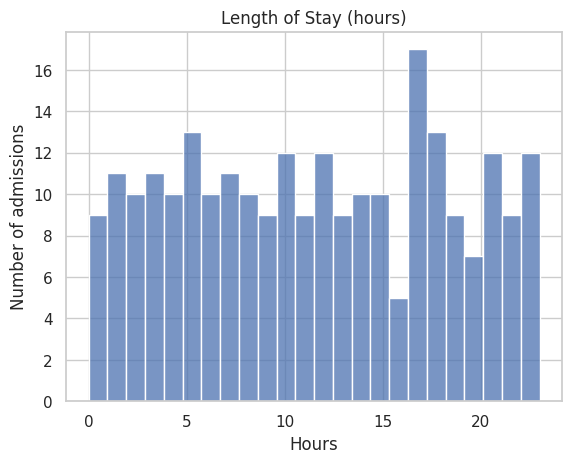

In [ ]:
print(df["length_of_stay_hours"].describe().round(2))

los = df["length_of_stay_hours"]

# IQR rule for outliers
q1 = los.quantile(0.25)
q3 = los.quantile(0.75)
low = q1 - 1.5 * (q3 - q1)
high = q3 + 1.5 * (q3 - q1)
print("\nOutliers by IQR rule:", ((los < low) | (los > high)).sum())

print("Stays of exactly 0 hours:", (los == 0).sum())
print("Stays of 1 hour or less: ", (los <= 1).sum())
print("Stays of 22 hours or more:", (los >= 22).sum())

sns.histplot(los, bins=24)
plt.title("Length of Stay (hours)")
plt.xlabel("Hours")
plt.ylabel("Number of admissions")
plt.show()

In [ ]:
# cross-check using the full dates + times
start = df["admission_date"] + pd.to_timedelta(df["admission_time"] + ":00")
end = df["discharge_date"] + pd.to_timedelta(df["discharge_time"] + ":00")
true_hours = (end - start).dt.total_seconds() / 3600

print("Rows with both dates:", true_hours.notnull().sum())
print("Impossible (negative) stays:", (true_hours < 0).sum())
print("Median true stay (hours):", true_hours.median())

# keep as a bonus column
df["total_stay_hours"] = true_hours.where(true_hours >= 0)

Rows with both dates: 238
Impossible (negative) stays: 5
Median true stay (hours): 178.0


**Comments on `length_of_stay_hours`**
- As specified, this metric uses only the **clock times**, with +24 h added for overnight cases, so it can only fall between 0 and 23.99 hours. It measures the time-of-day gap, not the full duration of the stay.
- **No statistical outliers** by the IQR rule, because the values are spread almost evenly across 0 to 23 hours.
- **Unusually short:** 9 patients have a stay of exactly **0 hours** (discharge time equals admission time). These are probably data-entry defaults or same-moment records and should be verified. Stays of 1 hour or less are also suspicious for an admission.
- **Unusually long:** stays near 22 to 23 hours are valid under this metric but are really "just under a full day", a limitation of using clock time only.
- The cross-check with full dates shows true stays of **days** (median about 7 days), and **5 records where the discharge is earlier than the admission** once dates are included (same-day records with an earlier discharge time). These are data-quality errors for the hospital to audit. `total_stay_hours` is added as a bonus column for anyone needing the real duration (invalid ones set to `NaN`).

---
# PART 3: Exploratory Data Analysis
Rows with a missing value in the plotted variable are excluded from that plot only.
## A. Univariate analysis
### 1. Histogram: `treatment_cost`

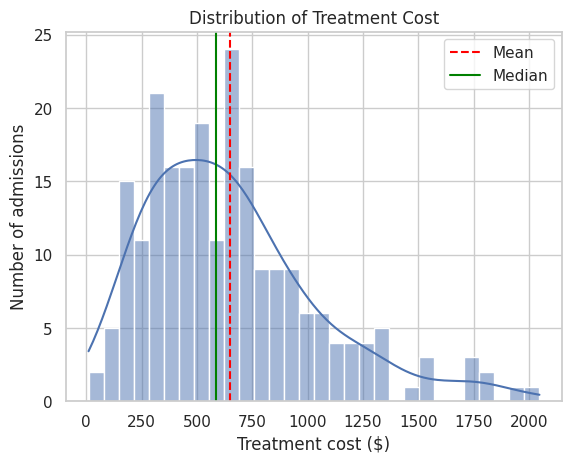

Count: 223
Mean:   651.59
Median: 585.36
Skewness: 1.07
Max: 2047.76
Admissions above $1,500: 10


In [ ]:
cost = df["treatment_cost"].dropna()

sns.histplot(cost, bins=30, kde=True)
plt.axvline(cost.mean(), color="red", linestyle="--", label="Mean")
plt.axvline(cost.median(), color="green", label="Median")
plt.title("Distribution of Treatment Cost")
plt.xlabel("Treatment cost ($)")
plt.ylabel("Number of admissions")
plt.legend()
plt.show()

print("Count:", len(cost))
print("Mean:  ", round(cost.mean(), 2))
print("Median:", round(cost.median(), 2))
print("Skewness:", round(cost.skew(), 2))
print("Max:", cost.max())
print("Admissions above $1,500:", (cost > 1500).sum())

**Interpretation:** The distribution is **right-skewed** (skewness about 1.07). Most admissions cost between roughly **$360 and $855** (the middle 50%), with a typical (median) cost of about **$585**. A small number of very expensive cases stretch the tail out to about **$2,050**, which pulls the mean (about $652) above the median. For budgeting and pricing the **median** is the more honest "typical" cost, while the expensive tail (10 admissions above $1,500) needs its own attention because those few cases carry a disproportionate share of revenue and risk.

### 2. Boxplot: `age`

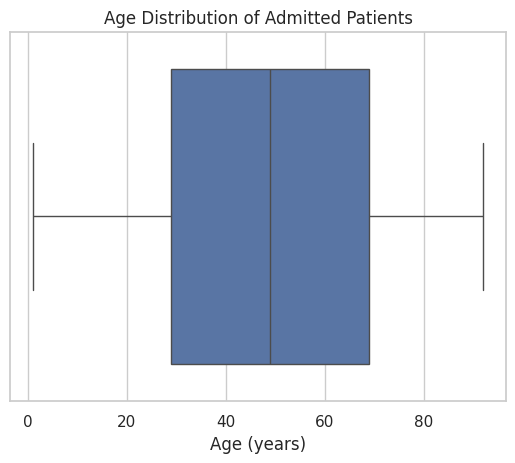

count    241.0
mean      48.3
std       25.0
min        1.0
25%       29.0
50%       49.0
75%       69.0
max       92.0
Name: age, dtype: float64

Outliers: 0
Children (under 18): 34 = 14 %
Elderly (65+):       70 = 29 %


In [ ]:
age = df["age"].dropna().astype(float)

sns.boxplot(x=age)
plt.title("Age Distribution of Admitted Patients")
plt.xlabel("Age (years)")
plt.show()

print(age.describe().round(1))

# find outliers with the IQR rule
q1 = age.quantile(0.25)
q3 = age.quantile(0.75)
low = q1 - 1.5 * (q3 - q1)
high = q3 + 1.5 * (q3 - q1)
print("\nOutliers:", ((age < low) | (age > high)).sum())

print("Children (under 18):", (age < 18).sum(), "=", round((age < 18).mean() * 100), "%")
print("Elderly (65+):      ", (age >= 65).sum(), "=", round((age >= 65).mean() * 100), "%")

**Outliers:** none. All ages from 1 to 92 fall inside the IQR fences (the whiskers reach the minimum and maximum).

**Interpretation:** The median age is **49**, with the middle half of patients aged **29 to 69**.

## B. Bivariate analysis
### 3. Scatter plot: `age` vs `treatment_cost`

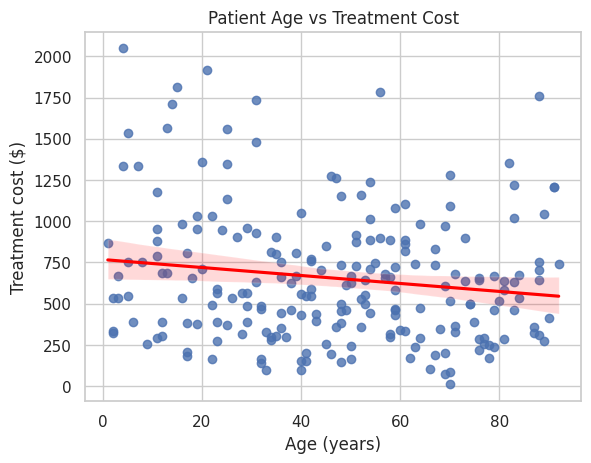

Patients used: 216
Correlation (r): -0.15
R-squared: 0.023


In [ ]:
data = df[["age", "treatment_cost"]].dropna().astype(float)

sns.regplot(data=data, x="age", y="treatment_cost", line_kws={"color": "red"})
plt.title("Patient Age vs Treatment Cost")
plt.xlabel("Age (years)")
plt.ylabel("Treatment cost ($)")
plt.show()

r = data["age"].corr(data["treatment_cost"])
print("Patients used:", len(data))
print("Correlation (r):", round(r, 3))
print("R-squared:", round(r ** 2, 3))

**Trend:** a very weak **negative** slope: Pearson r is about **-0.15** (Spearman about -0.12), so the line tilts slightly downward as age rises, but the points form a shapeless cloud.

**Interpretation:** **Age does not meaningfully influence cost.** Age explains only about 2% of the variation in cost (R-squared is roughly 0.02), and young and old patients show the full range from very cheap to over $1,500. Cost is therefore driven by **other factors** (diagnosis, department, payment route), not by how old the patient is,

### 4. Boxplot: `treatment_cost` by `payment_method`

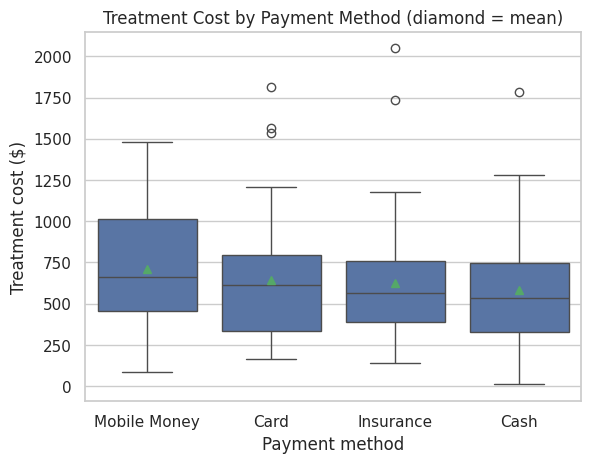

Unknown payment method (left out): 50
                count   mean    std    min    25%    50%     75%     max
payment_method                                                          
Card             42.0  645.0  385.0  164.0  337.0  615.0   796.0  1813.0
Cash             33.0  585.0  384.0   10.0  328.0  532.0   746.0  1783.0
Insurance        56.0  623.0  359.0  139.0  386.0  568.0   757.0  2048.0
Mobile Money     45.0  713.0  374.0   86.0  456.0  660.0  1017.0  1478.0


In [ ]:
# leave out the rows where the payment method is unknown
data = df[df["payment_method"] != "Unknown"].copy()
data["payment_method"] = data["payment_method"].astype(str)

sns.boxplot(data=data, x="payment_method", y="treatment_cost",
            order=["Mobile Money", "Card", "Insurance", "Cash"], showmeans=True)
plt.title("Treatment Cost by Payment Method (diamond = mean)")
plt.xlabel("Payment method")
plt.ylabel("Treatment cost ($)")
plt.show()

print("Unknown payment method (left out):", (df["payment_method"] == "Unknown").sum())
print(data.groupby("payment_method")["treatment_cost"].describe().round(0))



Interpretation:Mobile Money is associated with the highest treatment costs, and cash payers with the lowest. This is plausible: patients may be more willing to settle a large bill through a convenient mobile channel, while cash payers may avoid or defer expensive care. However, the boxes overlap heavily and every group has a similar spread (standard deviation about $360 to $385), with only 33 to 56 patients each, so this is a tendency to monitor, not proof. 50 patients with unknown payment method are excluded.

### 5. Violin plot: top 5 departments vs `treatment_cost`

Top 5: ['Cardiology', 'General', 'Orthopedics', 'Emergency', 'Pediatrics']


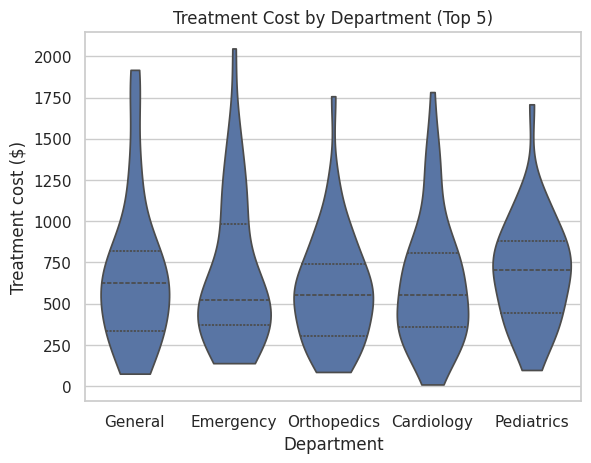

             count   mean    std    min    25%    50%    75%     max
department                                                          
Cardiology    60.0  629.0  389.0   10.0  357.0  553.0  807.0  1783.0
Emergency     44.0  673.0  442.0  139.0  371.0  524.0  985.0  2048.0
General       39.0  684.0  449.0   76.0  333.0  624.0  822.0  1918.0
Orthopedics   42.0  589.0  339.0   86.0  305.0  551.0  741.0  1758.0
Pediatrics    38.0  697.0  326.0   98.0  446.0  703.0  882.0  1709.0


In [ ]:
# 5 most frequent departments
top5 = df["department"].value_counts().head(5).index
print("Top 5:", list(top5))

data = df[df["department"].isin(top5)]

sns.violinplot(data=data, x="department", y="treatment_cost", inner="quartile", cut=0)
plt.title("Treatment Cost by Department (Top 5)")
plt.xlabel("Department")
plt.ylabel("Treatment cost ($)")
plt.show()

print(data.groupby("department")["treatment_cost"].describe().round(0))

 the hospital has exactly five departments, so the top 5 covers all of them.




Business insight:management should focus on Emergency(and General). They show the greatest cost volatility and the most extreme high-cost cases, which makes revenue and staffing hard to predict and exposes the hospital to unrecovered or mispriced bills. Pediatrics deserves a secondary look because it has the highest typical cost, but its costs are predictable, which makes it easier to price and plan for.

---
# PART 4: Insights and Business Recommendations

In [ ]:
cost = df["treatment_cost"].dropna()

# 1) share of total billing from the 10 most expensive admissions
top10_share = cost.sort_values(ascending=False).head(10).sum() / cost.sum()
print("Top 10 admissions =", round(top10_share * 100, 1), "% of total billed cost")

# 2) admissions with no cost, valued at the median cost
missing = df["treatment_cost"].isnull().sum()
print("Admissions with no cost:", missing, "= about $", round(missing * cost.median()), "unreported")

# 3) average cost by diagnosis
print("\nAverage cost by diagnosis:")
print(df.groupby("diagnosis")["treatment_cost"].mean().sort_values(ascending=False).round(0))

# 4) adults in the Pediatrics department
peds = df[df["department"] == "Pediatrics"]
print("\nPediatrics patients aged 18+:", (peds["age"] >= 18).sum(), "of", len(peds))

Top 10 admissions = 12.0 % of total billed cost
Admissions with no cost: 27 = about $ 15805 unreported

Average cost by diagnosis:
diagnosis
Asthma          835.0
Flu             672.0
Pneumonia       669.0
Diabetes        661.0
Hypertension    652.0
Malaria         624.0
Fracture        593.0
Typhoid         542.0
Name: treatment_cost, dtype: float64

Pediatrics patients aged 18+: 33 of 44


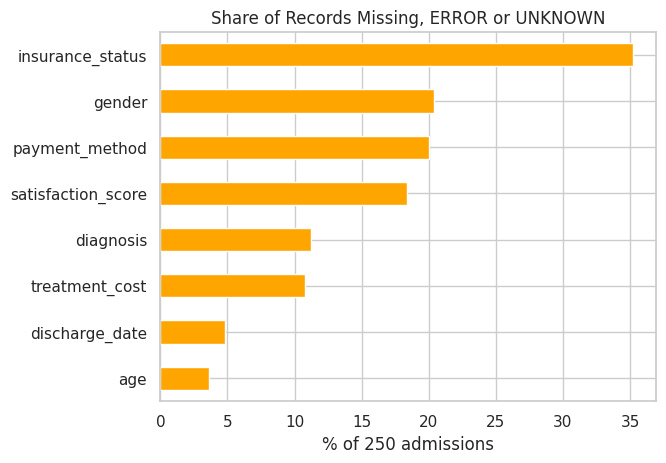

In [ ]:
# % of each column that is missing, ERROR or UNKNOWN in the raw file
percent_bad = {}
for col in df_raw.columns:
    bad = df_raw[col].isnull() | df_raw[col].isin(["ERROR", "UNKNOWN"])
    percent_bad[col] = bad.mean() * 100

percent_bad = pd.Series(percent_bad)
percent_bad = percent_bad[percent_bad > 0].sort_values()

percent_bad.plot(kind="barh", color="orange")
plt.title("Share of Records Missing, ERROR or UNKNOWN")
plt.xlabel("% of 250 admissions")
plt.show()

Key insights

Insight 1: Costs are skewed so a few expensive admissions matter a lot. What the data shows: the treatment-cost histogram is skewed (skewness about 1.07): median about 585 versus mean about 652 and 10 admissions above $1,500. Those top 10 admissions (4.5% of billed patients) generate 12% of all billed cost (see the evidence cell above). Why it matters: an average-based price or budget will under-estimate the exposure on complex cases; pricing and cash-flow planning should be based on the median and on explicit high-cost bands.

Insight 2: Emergency and General are the departments; Pediatrics is predictable. What the data shows: in the department violin plot Emergency (std 442 max about 2,050) and General (std about 449) have the widest longest-tailed distributions while Pediatrics has the highest median (703) but the narrowest spread (std about $326). Why it matters: volatile departments make staffing, stock and revenue forecasts unreliable; predictable ones can be priced with fixed packages.

Insight 3: Mobile Money payers carry the costs; cash payers the lowest. What the data shows: the payment-method boxplot puts Mobile Money highest (median 660 mean about 713) and Cash lowest (median about 532 mean about 585). Why it matters: it suggests expensive care is being settled digitally so mobile payments are a revenue- channel (any outage or fee change hits the biggest bills). The difference is modest and the boxes overlap so it should be tracked over time than acted on as a firm rule.

Insight 4: Age is not a cost driver. What the data shows: the age vs cost scatter plot has r of about -0.15 and R-squared of 0.02. Why it matters: age-based surcharges or discounts would not reflect cost; diagnosis and department (for example Asthma admissions have the highest average cost at about $835) are better levers.

Insight 5: The reporting problem itself is the finding. What the data shows: the data-quality bar chart above shows 35% of insurance statuses 20% of payment methods 20% of genders and 11% of treatment costs are unusable plus 28 diagnoses recorded as "ERROR". Also 33 of 44 Pediatrics admissions are patients aged 18 or over and 5 records have a discharge earlier than the admission. Why it matters: this directly explains managements complaint about "inconsistencies in cost reporting". The 27 admissions with no cost represent an estimated $15,800 in unreported or unbilled revenue at the median cost and department coding that does not match patient age makes department-level costing unreliable.

Recommendations for hospital management

Recommendation 1: Fix data capture at the point of admission (reporting and insurance strategy). Replace free-text fields with dropdowns (payment method, insurance status, gender, diagnosis) validate that cost is numeric and present before a record can be closed and block impossible dates and times. Run a one-off audit of the 27 admissions with missing costs and the 33 adult patients booked into Pediatrics. Verifying insurance status at registration (35% is Unknown") will also let finance pursue insurer claims properly. Expected result: cost reports and recovery of unbilled revenue.

Recommendation 2: Price and staff by cost risk not by the average (pricing and staffing strategy). Set the price list from median costs and create fixed-price packages for predictable departments and conditions (Pediatrics and common conditions) while using pre-authorisation and itemised estimates for high-variance Emergency and General admissions and for costs above about $1,500. Align. General staffing and stock buffers to this volatility and make sure the mobile-money channel is reliable and integrated with billing because it carries the highest-value bills. Expected result: pricing surprises, better cash-flow forecasting and better use of staff.

Limitations: 11% of costs are missing several categorical fields are 20 to 35% unknown and group sizes are small (about 40 to 60 per department or payment method) so differences, between groups are indicative rather than statistically proven.

In [ ]:
# save the cleaned data
df.to_csv("afya_bora_hospital_cleaned.csv", index=False)
print("Saved:", df.shape)

Saved: (250, 17)
